In [1]:
from pathlib import Path

# Energy-specific data contract
EXPECTED_DATA_ROWS = 1000

# Paths and filenames
# Locate the repository data from the project root or a notebook directory.
REPO_ROOT = next((parent for parent in (Path.cwd(), *Path.cwd().parents)
                  if (parent / 'data').is_dir() and (parent / 'src').is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Run this notebook from within the rhic-bes-ml-calibration repository.')
DATA_DIR = REPO_ROOT / 'data'
ARTIFACT_DIR = Path('artifacts') / 'iHKMe_spectra_14-5_v1.9.0'
SPECTRA_FILENAME = 'ihkm_data_14-5_v4.txt'
TARGETS_FILENAME = '14_5_ML_new.csv'
EXPERIMENT_FILENAME = 'exp_data_14-5_v3.txt'
EXPERIMENT_ERRORS_FILENAME = 'err_data_14-5_v3.txt'
CUTS_FILENAME = 'cuts_14-5_v3.txt'
SPLIT_DEFINITION_DIR = ARTIFACT_DIR / 'split_definitions'
SPLIT_ARCHIVE_TEMPLATE = 'seed_{seed}.npz'
SPLIT_AUDIT_FILENAME = 'split_audit.csv'


In [2]:
import random

import pandas as pd
import numpy as np
import math
import tensorflow as tf

SEED = 1729
TARGET_NAMES = ['tau_0', 'tau_rel', 'tau_th', 'eta_s', 'e_sw', 'Rgauss']
VALIDATION_ROWS = 100
PRIMARY_SPLIT_SEEDS = (101, 211, 307, 401, 503)
# The notebook trains on one reproducible split at a time. Change this to any
# value in PRIMARY_SPLIT_SEEDS to measure sensitivity to the validation split.
ACTIVE_SPLIT_SEED = PRIMARY_SPLIT_SEEDS[0]

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as exc:
    print(f'Deterministic TensorFlow operations are unavailable: {exc}')


def load_pion_data(filename):
    return pd.read_csv(DATA_DIR / filename, sep='\t', header=None)

spectra_raw = load_pion_data(SPECTRA_FILENAME)
complete_source_indices = spectra_raw.dropna().index.to_numpy(dtype=int)
spectra_all = spectra_raw.loc[complete_source_indices].reset_index(drop=True)

targets_path = DATA_DIR / TARGETS_FILENAME
dataY_raw = pd.read_csv(targets_path, sep=',')
dataY = dataY_raw.loc[complete_source_indices].reset_index(drop=True)

spectra_experiment = load_pion_data(EXPERIMENT_FILENAME)
spectra_experiment_errors = load_pion_data(EXPERIMENT_ERRORS_FILENAME)
cuts = load_pion_data(CUTS_FILENAME).iloc[0].to_numpy(dtype=int)

assert list(dataY.loc[:, TARGET_NAMES].columns) == TARGET_NAMES
assert len(spectra_all) == len(dataY) == EXPECTED_DATA_ROWS
assert spectra_all.shape[1] == spectra_experiment.shape[1] == spectra_experiment_errors.shape[1] == int(cuts[-1])
assert len(spectra_experiment) == len(spectra_experiment_errors) == 1
assert np.isfinite(spectra_experiment_errors.to_numpy()).all()
assert (spectra_experiment_errors.to_numpy() >= 0).all()

def parameter_key(row):
    return tuple(row[name] for name in TARGET_NAMES)

PARAMETER_GROUPS = {}
for row_index, row in dataY.loc[:, TARGET_NAMES].iterrows():
    PARAMETER_GROUPS.setdefault(parameter_key(row), []).append(int(row_index))

def make_seeded_group_split(seed):
    """Select exactly VALIDATION_ROWS without splitting repeated parameters."""
    rng = np.random.default_rng(seed)
    groups = list(PARAMETER_GROUPS.values())
    shuffled_groups = [groups[i] for i in rng.permutation(len(groups))]

    # Subset-sum dynamic programming keeps whole parameter groups together and
    # deterministically finds an exact-size validation set when one exists.
    choices = {0: []}
    for group in shuffled_groups:
        group_size = len(group)
        for count, selected_groups in list(choices.items())[::-1]:
            new_count = count + group_size
            if new_count <= VALIDATION_ROWS and new_count not in choices:
                choices[new_count] = selected_groups + [group]
        if VALIDATION_ROWS in choices:
            break
    if VALIDATION_ROWS not in choices:
        sizes = sorted(len(group) for group in groups)
        raise RuntimeError(
            f'Seed {seed}: cannot form exactly {VALIDATION_ROWS} validation rows '
            f'from parameter-group sizes {sizes}'
        )

    validation_indices = np.sort(np.asarray(
        [index for group in choices[VALIDATION_ROWS] for index in group], dtype=int
    ))
    validation_mask = np.zeros(len(dataY), dtype=bool)
    validation_mask[validation_indices] = True
    train_indices = np.flatnonzero(~validation_mask)
    return train_indices, validation_indices

def audit_split(split_name, train_indices, validation_indices):
    assert len(validation_indices) == VALIDATION_ROWS
    assert len(train_indices) + len(validation_indices) == len(dataY)
    assert not np.intersect1d(train_indices, validation_indices).size
    assignments = {}
    for subset, indices in [('train', train_indices), ('validation', validation_indices)]:
        for _, row in dataY.iloc[indices].loc[:, TARGET_NAMES].iterrows():
            assignments.setdefault(parameter_key(row), set()).add(subset)
    crossing = sum(len(subsets) > 1 for subsets in assignments.values())
    assert crossing == 0, f'{split_name}: {crossing} parameter groups cross the split'
    return dict(
        split=split_name,
        train_rows=len(train_indices),
        validation_rows=len(validation_indices),
        train_parameter_groups=dataY.iloc[train_indices].loc[:, TARGET_NAMES].drop_duplicates().shape[0],
        validation_parameter_groups=dataY.iloc[validation_indices].loc[:, TARGET_NAMES].drop_duplicates().shape[0],
        parameter_groups_crossing_split=crossing,
    )

split_plans = {}
audit_rows = []
SPLIT_DEFINITION_DIR.mkdir(parents=True, exist_ok=True)
for split_seed in PRIMARY_SPLIT_SEEDS:
    split_name = f'seed_{split_seed}'
    train_indices, validation_indices = make_seeded_group_split(split_seed)
    split_plans[split_seed] = (train_indices, validation_indices)
    audit_rows.append(audit_split(split_name, train_indices, validation_indices))
    np.savez_compressed(
        SPLIT_DEFINITION_DIR / SPLIT_ARCHIVE_TEMPLATE.format(seed=split_seed),
        train_indices=train_indices,
        validation_indices=validation_indices,
        train_source_indices=complete_source_indices[train_indices],
        validation_source_indices=complete_source_indices[validation_indices],
    )

split_audit = pd.DataFrame(audit_rows)
split_audit.to_csv(SPLIT_DEFINITION_DIR / SPLIT_AUDIT_FILENAME, index=False)
display(split_audit)

train_indices, validation_indices = split_plans[ACTIVE_SPLIT_SEED]
spectra_train = spectra_all.iloc[train_indices].reset_index(drop=True)
spectra_validation = spectra_all.iloc[validation_indices].reset_index(drop=True)
print(f'Active split: seed_{ACTIVE_SPLIT_SEED}; train={len(train_indices)}, validation={len(validation_indices)}')
print(cuts)


2026-09-02 15:02:54.071422: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-02 15:02:54.082463: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1788350574.094962 3311300 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1788350574.098508 3311300 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-09-02 15:02:54.111449: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

,split,train_rows,validation_rows,train_parameter_groups,validation_parameter_groups,parameter_groups_crossing_split
0,seed_101,900,100,900,100,0
1,seed_211,900,100,900,100,0
2,seed_307,900,100,900,100,0
3,seed_401,900,100,900,100,0
4,seed_503,900,100,900,100,0


Active split: seed_101; train=900, validation=100
[ 25  50  73  96 118 140 148 152 156 160]


In [3]:
Y_train = dataY.iloc[train_indices].loc[:, TARGET_NAMES].reset_index(drop=True)
Y_valid = dataY.iloc[validation_indices].loc[:, TARGET_NAMES].reset_index(drop=True)
if 'eos' in dataY.columns:
    eos_train = dataY.iloc[train_indices].loc[:, ['eos']].reset_index(drop=True)
    eos_valid = dataY.iloc[validation_indices].loc[:, ['eos']].reset_index(drop=True)
Y_train.head()


,tau_0,tau_rel,tau_th,eta_s,e_sw,Rgauss
0,1.30,1.2,3.10,0.30,0.42,1.04
1,1.95,1.5,3.55,0.25,0.31,0.70
2,1.50,1.4,2.95,0.19,0.45,0.71
3,1.35,1.2,2.55,0.16,0.46,1.23
4,2.00,0.7,2.85,0.30,0.33,0.96


In [4]:
X_pimin_train = spectra_train.loc[:, :cuts[0]-1]
X_pimin_val = spectra_validation.loc[:, :cuts[0]-1]
X_pimin_exp = spectra_experiment.loc[:, :cuts[0]-1]
X_pimin_train.head()

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,23,24
0,118.0350,86.6370,64.3036,46.6658,35.3555,26.3157,20.2729,15.7137,12.12650,9.37326,...,6.67905,4.18384,2.56851,1.680670,1.090990,0.734771,0.466127,0.321712,0.204071,0.134859
1,75.6875,56.3485,40.3744,31.6074,23.0995,17.1987,12.7771,9.6503,8.00683,5.83622,...,3.97634,2.47958,1.54952,0.971543,0.614625,0.405262,0.242636,0.166310,0.099884,0.067438
2,91.4845,67.5361,48.5177,35.5724,26.4686,19.7595,14.8105,11.2564,8.63651,6.74104,...,4.69698,2.86849,1.83438,1.113960,0.741129,0.480398,0.290448,0.195064,0.128143,0.091876
3,127.6750,92.5521,67.0557,49.1588,36.4645,27.2613,20.3713,15.3162,12.03220,8.68683,...,6.20929,3.87691,2.35328,1.393020,0.865466,0.583179,0.371633,0.228640,0.148589,0.093874
4,88.4976,64.1443,47.6168,34.0920,25.3662,19.1518,15.2682,11.2513,8.94244,6.62369,...,4.61746,2.96065,1.85592,1.315890,0.740025,0.497251,0.313583,0.213279,0.133246,0.084508


In [5]:
X_piplus_train = spectra_train.loc[:, cuts[0]:cuts[1]-1]
X_piplus_val = spectra_validation.loc[:, cuts[0]:cuts[1]-1]
X_piplus_exp = spectra_experiment.loc[:, cuts[0]:cuts[1]-1]
X_piplus_train.head()

,25,26,27,28,29,30,31,32,33,34,...,40,41,42,43,44,45,46,47,48,49
0,102.0240,75.8219,56.6080,43.0909,32.0863,25.8061,19.1417,14.74500,11.49300,8.97450,...,6.11246,3.96103,2.57052,1.578190,1.059200,0.678508,0.458244,0.297498,0.195878,0.132291
1,66.6758,52.2095,37.5896,28.8415,21.7201,15.4842,12.3341,9.23474,6.94703,5.69905,...,3.92617,2.30845,1.47395,0.913594,0.604700,0.382701,0.302708,0.135136,0.098118,0.060766
2,80.0024,59.1357,43.5010,32.5259,24.5233,19.6879,13.9088,11.31920,8.28849,6.51491,...,4.46908,2.71869,1.75783,1.095880,0.678863,0.461752,0.316208,0.198280,0.119942,0.083613
3,110.8120,82.5968,61.3286,45.1350,33.8432,25.0399,19.2354,14.64250,11.22320,8.55075,...,5.91755,3.63438,2.13699,1.376180,0.860074,0.557638,0.394055,0.227220,0.138113,0.092285
4,73.4103,54.9464,41.4758,31.1614,23.6069,17.7773,13.9805,10.47910,8.25016,6.58807,...,4.59020,2.93464,1.75995,1.118420,0.721161,0.445587,0.289057,0.199365,0.124102,0.095384


In [6]:
X_Kmin_train = spectra_train.loc[:, cuts[1]:cuts[2]-1]
X_Kmin_val = spectra_validation.loc[:, cuts[1]:cuts[2]-1]
X_Kmin_exp = spectra_experiment.loc[:, cuts[1]:cuts[2]-1]
X_Kmin_train.head()

,50,51,52,53,54,55,56,57,58,59,...,63,64,65,66,67,68,69,70,71,72
0,4.63757,4.45548,3.91556,3.37958,2.94374,2.50951,2.11665,1.76393,1.572490,1.409130,...,1.490810,1.005610,0.677858,0.499756,0.336006,0.237811,0.169718,0.122388,0.075482,0.048701
1,2.90757,2.78017,2.43595,2.10373,1.76457,1.58227,1.37018,1.08722,0.956405,0.823400,...,0.889902,0.588588,0.421953,0.287479,0.201170,0.131768,0.086911,0.061935,0.044096,0.030266
2,3.61080,3.22774,2.85963,2.41749,2.11044,1.88026,1.52524,1.28130,1.155520,0.921629,...,1.038580,0.715522,0.489437,0.329738,0.228908,0.157789,0.115021,0.072670,0.050710,0.031173
3,5.55474,4.77841,4.18414,3.71535,3.08328,2.65057,2.17716,1.86139,1.531740,1.338550,...,1.435150,0.957186,0.666774,0.467775,0.300374,0.204305,0.130788,0.090279,0.066242,0.036440
4,3.47294,3.11543,2.91522,2.47019,2.09845,1.81678,1.56355,1.30750,1.095380,1.040890,...,1.068130,0.707084,0.501184,0.339126,0.231800,0.178349,0.123340,0.073832,0.054365,0.038176


In [7]:
X_Kplus_train = spectra_train.loc[:, cuts[2]:cuts[3]-1]
X_Kplus_val = spectra_validation.loc[:, cuts[2]:cuts[3]-1]
X_Kplus_exp = spectra_experiment.loc[:, cuts[2]:cuts[3]-1]
X_Kplus_train.head()

,73,74,75,76,77,78,79,80,81,82,...,86,87,88,89,90,91,92,93,94,95
0,8.82648,7.79772,7.01989,5.69598,5.05118,5.85393,3.85184,3.29597,2.80314,2.30224,...,2.55269,1.79698,1.254460,0.942151,0.658869,0.436392,0.311324,0.216710,0.149392,0.107255
1,5.75049,4.95397,4.39239,3.81790,3.18778,2.79326,2.35719,1.93013,1.76128,1.78210,...,1.77169,1.09783,0.739160,0.530398,0.357968,0.236673,0.163592,0.108403,0.072879,0.051077
2,6.76036,5.71720,5.24527,4.65483,3.99604,5.66120,2.83273,2.41324,1.96660,1.73297,...,1.84979,1.31525,0.896768,0.638528,0.426435,0.284841,0.207323,0.139874,0.093967,0.064306
3,9.73465,8.60158,7.40913,6.48558,5.54859,4.68811,3.96480,3.20415,2.73439,2.38145,...,2.55792,1.78536,1.172610,0.794493,0.552932,0.367456,0.240529,0.164808,0.107445,0.076415
4,6.40318,5.72412,4.88421,4.26096,3.62289,3.17690,2.82672,2.25183,2.10691,1.65729,...,1.88210,1.34163,0.876641,0.608416,0.431325,0.351715,0.204716,0.178115,0.101985,0.059122


In [8]:
X_p_train = spectra_train.loc[:, cuts[3]:cuts[4]-1]
X_p_val = spectra_validation.loc[:, cuts[3]:cuts[4]-1]
X_p_exp = spectra_experiment.loc[:, cuts[3]:cuts[4]-1]
X_p_train.head()

,96,97,98,99,100,101,102,103,104,105,...,108,109,110,111,112,113,114,115,116,117
0,5.85764,5.38880,5.26816,4.74522,4.48632,4.13395,3.64868,3.34674,3.01607,2.73012,...,4.31014,3.49771,2.87310,2.22984,1.75140,1.361990,1.011780,0.762101,0.563379,0.427997
1,4.52418,4.19444,3.86962,3.63564,3.19865,2.96562,2.63310,2.40359,2.03280,1.86041,...,3.08214,2.51835,1.94660,1.50748,1.08744,0.832249,0.615868,0.455853,0.308948,0.235746
2,5.04684,4.78393,4.37061,4.13305,3.77932,3.39502,3.01972,2.79703,2.50870,2.13935,...,3.58717,2.90837,2.32402,1.83313,1.37737,1.067780,0.816690,0.587079,0.438980,0.316062
3,6.61771,6.15367,5.57121,5.01752,4.70932,4.15594,3.75713,3.41599,3.05163,2.68392,...,4.43265,3.58658,2.86778,2.04366,1.66118,1.170050,0.856763,0.619617,0.433087,0.311980
4,4.60782,4.14226,3.91931,3.60417,3.49307,3.10801,2.80193,2.46131,2.28663,1.97260,...,3.30055,2.63163,2.12961,1.66259,1.29505,0.985419,0.737418,0.521563,0.397166,0.280100


In [9]:
X_ap_train = spectra_train.loc[:, cuts[4]:cuts[5]-1]
X_ap_val = spectra_validation.loc[:, cuts[4]:cuts[5]-1]
X_ap_exp = spectra_experiment.loc[:, cuts[4]:cuts[5]-1]
X_ap_train.head()

,118,119,120,121,122,123,124,125,126,127,...,130,131,132,133,134,135,136,137,138,139
0,0.309327,0.323747,0.308014,0.278611,0.257761,0.230046,0.236447,0.186541,0.197600,0.167983,...,0.243903,0.211494,0.182791,0.152879,0.109598,0.081765,0.065114,0.040426,0.036904,0.024077
1,0.249302,0.243062,0.209367,0.200495,0.242128,0.185488,0.186093,0.139811,0.145601,0.128134,...,0.213808,0.162952,0.136867,0.104593,0.070122,0.061010,0.049293,0.034503,0.027734,0.016295
2,0.227231,0.289264,0.226025,0.195292,0.191499,0.193803,0.163501,0.157444,0.124849,0.114386,...,0.192651,0.160473,0.119618,0.100952,0.085224,0.070479,0.047329,0.032082,0.024115,0.016891
3,0.398714,0.417221,0.341979,0.304197,0.324709,0.271687,0.277945,0.228673,0.200909,0.207423,...,0.298198,0.253309,0.204166,0.155953,0.124931,0.083265,0.076134,0.039685,0.035334,0.022445
4,0.227080,0.231535,0.210011,0.217981,0.214248,0.193538,0.146709,0.158658,0.122851,0.124045,...,0.203893,0.152683,0.123448,0.110633,0.084131,0.061149,0.044103,0.039592,0.027873,0.016393


In [10]:
X_v2_train = spectra_train.loc[:, cuts[5]:cuts[6]-1]
X_v2_val = spectra_validation.loc[:, cuts[5]:cuts[6]-1]
X_v2_exp = spectra_experiment.loc[:, cuts[5]:cuts[6]-1]
X_v2_train.head()

,140,141,142,143,144,145,146,147
0,0.022009,0.038992,0.041521,0.048182,0.062138,0.062337,0.074158,0.086499
1,0.033196,0.042724,0.054929,0.062925,0.075608,0.081915,0.093683,0.104405
2,0.025843,0.046154,0.053773,0.040248,0.074690,0.087119,0.101005,0.102892
3,0.026668,0.042280,0.054636,0.065490,0.079393,0.085754,0.098584,0.107730
4,0.025702,0.038337,0.045510,0.051616,0.071083,0.076141,0.083037,0.093925


In [11]:
X_Rout_train = spectra_train.loc[:, cuts[6]:cuts[7]-1]
X_Rout_val = spectra_validation.loc[:, cuts[6]:cuts[7]-1]
X_Rout_exp = spectra_experiment.loc[:, cuts[6]:cuts[7]-1]
X_Rout_train.head()

,148,149,150,151
0,4.53249,4.24503,3.84535,3.53213
1,4.70366,4.23367,3.85943,3.49541
2,4.23722,4.04788,3.73311,3.31827
3,4.75116,4.49902,4.10325,3.69291
4,4.53532,4.12992,3.86635,3.43416


In [12]:
X_Rside_train = spectra_train.loc[:, cuts[7]:cuts[8]-1]
X_Rside_val = spectra_validation.loc[:, cuts[7]:cuts[8]-1]
X_Rside_exp = spectra_experiment.loc[:, cuts[7]:cuts[8]-1]
X_Rside_train.head()

,152,153,154,155
0,3.72046,3.41180,3.21759,2.99513
1,3.35611,3.27764,3.07457,2.89683
2,3.47776,3.24230,3.03288,2.85412
3,3.73175,3.49441,3.25001,3.03586
4,3.44896,3.31211,3.12175,2.91740


In [13]:
X_Rlong_train = spectra_train.loc[:, cuts[8]:]
X_Rlong_val = spectra_validation.loc[:, cuts[8]:]
X_Rlong_exp = spectra_experiment.loc[:, cuts[8]:]
X_Rlong_train.head()

,156,157,158,159
0,5.31944,4.34690,3.63105,2.99104
1,4.49692,3.98871,3.28936,2.77209
2,4.93876,4.07229,3.33583,2.76132
3,5.38646,4.38932,3.65629,3.03055
4,4.89499,4.14492,3.39871,2.84917


In [14]:
from sklearn.preprocessing import StandardScaler

scaler_pimin = StandardScaler()
X_pimin_train = tf.math.log(X_pimin_train)
X_pimin_val = tf.math.log(X_pimin_val)
X_pimin_exp = tf.math.log(X_pimin_exp)
X_pimin_train = scaler_pimin.fit_transform(X_pimin_train)
X_pimin_val = scaler_pimin.transform(X_pimin_val)
X_pimin_exp = scaler_pimin.transform(X_pimin_exp)

scaler_piplus = StandardScaler()
X_piplus_train = tf.math.log(X_piplus_train)
X_piplus_val = tf.math.log(X_piplus_val)
X_piplus_exp = tf.math.log(X_piplus_exp)
X_piplus_train = scaler_piplus.fit_transform(X_piplus_train)
X_piplus_val = scaler_piplus.transform(X_piplus_val)
X_piplus_exp = scaler_piplus.transform(X_piplus_exp)

scaler_Kmin = StandardScaler()
X_Kmin_train = tf.math.log(X_Kmin_train)
X_Kmin_val = tf.math.log(X_Kmin_val)
X_Kmin_exp = tf.math.log(X_Kmin_exp)
X_Kmin_train = scaler_Kmin.fit_transform(X_Kmin_train)
X_Kmin_val = scaler_Kmin.transform(X_Kmin_val)
X_Kmin_exp = scaler_Kmin.transform(X_Kmin_exp)

scaler_Kplus = StandardScaler()
X_Kplus_train = tf.math.log(X_Kplus_train)
X_Kplus_val = tf.math.log(X_Kplus_val)
X_Kplus_exp = tf.math.log(X_Kplus_exp)
X_Kplus_train = scaler_Kplus.fit_transform(X_Kplus_train)
X_Kplus_val = scaler_Kplus.transform(X_Kplus_val)
X_Kplus_exp = scaler_Kplus.transform(X_Kplus_exp)

scaler_p = StandardScaler()
X_p_train = tf.math.log(X_p_train)
X_p_val = tf.math.log(X_p_val)
X_p_exp = tf.math.log(X_p_exp)
X_p_train = scaler_p.fit_transform(X_p_train)
X_p_val = scaler_p.transform(X_p_val)
X_p_exp = scaler_p.transform(X_p_exp)

scaler_ap = StandardScaler()
X_ap_train = tf.math.log(X_ap_train)
X_ap_val = tf.math.log(X_ap_val)
X_ap_exp = tf.math.log(X_ap_exp)
X_ap_train = scaler_ap.fit_transform(X_ap_train)
X_ap_val = scaler_ap.transform(X_ap_val)
X_ap_exp = scaler_ap.transform(X_ap_exp)

scaler_v2 = StandardScaler()
X_v2_train = scaler_v2.fit_transform(X_v2_train)
X_v2_val = scaler_v2.transform(X_v2_val)
X_v2_exp = scaler_v2.transform(X_v2_exp)

scaler_Rout = StandardScaler()
X_Rout_train = scaler_Rout.fit_transform(X_Rout_train)
X_Rout_val = scaler_Rout.transform(X_Rout_val)
X_Rout_exp = scaler_Rout.transform(X_Rout_exp)

scaler_Rside = StandardScaler()
X_Rside_train = scaler_Rside.fit_transform(X_Rside_train)
X_Rside_val = scaler_Rside.transform(X_Rside_val)
X_Rside_exp = scaler_Rside.transform(X_Rside_exp)

scaler_Rlong = StandardScaler()
X_Rlong_train = scaler_Rlong.fit_transform(X_Rlong_train)
X_Rlong_val = scaler_Rlong.transform(X_Rlong_val)
X_Rlong_exp = scaler_Rlong.transform(X_Rlong_exp)

X_pimin_train[:5]

2026-09-02 15:03:04.954146: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_UNKNOWN: unknown error


array([[ 0.77556817,  0.8395885 ,  0.9286137 ,  0.8718445 ,  0.93367998,
         0.78849317,  0.84138617,  1.03247413,  0.93655486,  1.03520537,
         1.16605018,  1.06216465,  0.88546777,  0.93210147,  0.99698889,
         1.13069935,  1.18500452,  1.10493158,  1.15297309,  1.2056322 ,
         1.33282704,  1.16688031,  1.38350978,  1.22638907,  1.21814421],
       [-1.83642027, -1.62845447, -1.66547408, -1.24827348, -1.3050228 ,
        -1.46601227, -1.41392639, -1.35038178, -1.07902931, -1.12860892,
        -1.08146964, -1.20534452, -1.40502295, -1.40512117, -1.12789548,
        -1.15138971, -0.94296713, -0.78717058, -0.82905756, -0.70431557,
        -0.49917063, -0.71779495, -0.42118592, -0.57619904, -0.45728149],
       [-0.72221021, -0.58938251, -0.64141148, -0.60520387, -0.58894089,
        -0.73028879, -0.69242122, -0.59796642, -0.71143665, -0.47034129,
        -0.38162122, -0.44900572, -0.66608405, -0.66185087, -0.62050791,
        -0.41847447, -0.3503189 , -0.1553426 , -0

In [15]:
output_shape = 6

scalerY = StandardScaler()
Y_train_norm = scalerY.fit_transform(Y_train)
Y_valid_norm = scalerY.transform(Y_valid)
Y_valid_norm[:5]

array([[ 0.27749722,  0.94917746, -0.45729299, -0.40703559,  0.70118659,
         1.48550695],
       [ 0.81778386, -0.44819394, -0.39215154, -0.25128218, -1.03585699,
         0.14613118],
       [ 1.35807049,  0.483387  ,  1.62723346, -1.80881633,  1.56970839,
        -0.32913119],
       [-0.26278942,  0.71628223, -0.52243444,  1.6177588 , -1.38326571,
         1.44230128],
       [-1.20829103, -1.37977488, -1.23899041, -1.80881633,  0.00636916,
        -1.32286161]])

In [16]:
def custom_loss_log_sq(y_true, y_pred):
    delta = (y_true-y_pred)
    return tf.math.reduce_mean(tf.math.log(tf.math.reduce_mean(tf.math.square(delta), axis=0)))


def error_loss(y_true, y_pred):

    # Split predictions into normalized means and normalized signed scales.
    means = y_pred[:, :output_shape]
    log_variances = y_pred[:, output_shape:]
    variances = tf.nn.softplus(log_variances)
    
    # Variance-weighted squared error
    squared_error = tf.math.square(means - y_true)

     # Loss: (error / variance) + log(variance) (encourages realistic uncertainty estimates)
    loss = squared_error / variances + tf.math.log(variances)
    
    # Return mean loss across all samples and parameters
    return tf.reduce_mean(loss)

def error_loss2(y_true, y_pred):

    # Split the predictions into means and log-variances
    means = y_pred[:, :output_shape]
    scales = y_pred[:, output_shape:]

    term1 = tf.math.square(means - y_true)
    term2 = tf.math.square(tf.math.square(means - y_true) - tf.math.square(scales))
    return tf.reduce_mean(term1 + term2)

def custom_accuracy(y_true, y_pred):
    means = y_pred[:, :output_shape]
    return tf.reduce_mean(tf.square(y_true - means)) 

#x = tf.constant([[1.1, 1., 1., 1.1, 0.], [2., 2., 2., 2., 1.]])
#y = tf.constant([[1., 2., 1., 1., 0., 1., 1., 1., 1., 1.], [2., 2., 1., 2., 1., 0., 0., 0., 0., 0.]])
#print(error_loss(x,y))

In [17]:
# Output contract for error_loss2: the first six outputs are normalized
# predictive means and the last six are normalized signed scales. Squaring
# the scales gives each member's aleatoric variance.
def aggregate_ensemble(predictions, output_shape=output_shape):
    predictions = np.asarray(predictions)
    if predictions.ndim != 3 or predictions.shape[-1] != 2 * output_shape:
        raise ValueError(
            f"Expected predictions with shape (members, samples, {2 * output_shape}), "
            f"got {predictions.shape}"
        )

    member_means_norm = predictions[..., :output_shape]
    member_scales_norm = predictions[..., output_shape:]
    ensemble_mean_norm = member_means_norm.mean(axis=0)
    aleatoric_variance_norm = np.square(member_scales_norm).mean(axis=0)
    epistemic_variance_norm = member_means_norm.var(axis=0, ddof=0)
    total_variance_norm = aleatoric_variance_norm + epistemic_variance_norm
    return (ensemble_mean_norm, aleatoric_variance_norm,
            epistemic_variance_norm, total_variance_norm)


def ensemble_to_physical(mean_norm, aleatoric_var_norm, epistemic_var_norm, total_var_norm):
    mean_physical = scalerY.inverse_transform(mean_norm)
    aleatoric_std_physical = np.sqrt(aleatoric_var_norm) * scalerY.scale_
    epistemic_std_physical = np.sqrt(epistemic_var_norm) * scalerY.scale_
    total_std_physical = np.sqrt(total_var_norm) * scalerY.scale_
    return (mean_physical, aleatoric_std_physical,
            epistemic_std_physical, total_std_physical)# Monte Carlo measurement-error contract. The six spectra are sampled in log
# space using sigma_log ~= sigma_raw / center, matching the unified notebook.
# v2 is sampled in native space. HBT is not an input to this network.
MC_SEED = 1729
EXPERIMENTAL_DRAWS = 2000
NOISY_CLOSURE_DRAWS = 200

observable_bounds = [0, *cuts[:7].astype(int).tolist()]
observable_scalers = [
    scaler_pimin, scaler_piplus, scaler_Kmin, scaler_Kplus,
    scaler_p, scaler_ap, scaler_v2,
]


def make_measurement_error_inputs(centers, draws, seed):
    centers = np.asarray(centers, dtype=np.float64)
    errors = spectra_experiment_errors.to_numpy(dtype=np.float64)
    if centers.ndim != 2 or errors.shape[0] != 1:
        raise ValueError("Expected 2D centers and one row of experimental errors")
    rng = np.random.default_rng(seed)
    transformed_inputs = []
    for observable_index, scaler in enumerate(observable_scalers):
        start = observable_bounds[observable_index]
        stop = observable_bounds[observable_index + 1]
        center = centers[:, start:stop]
        sigma_raw = errors[:, start:stop]
        if observable_index < 6:
            if not np.all(center > 0):
                raise ValueError("All spectrum centers must be positive for log sampling")
            location = np.log(center)
            scale = sigma_raw / center
        else:
            location = center
            scale = np.broadcast_to(sigma_raw, center.shape)
        sampled = rng.normal(
            location[:, None, :],
            scale[:, None, :],
            size=(center.shape[0], draws, center.shape[1]),
        )
        sampled_2d = sampled.reshape(center.shape[0] * draws, center.shape[1])
        transformed_inputs.append(scaler.transform(sampled_2d).astype(np.float32))
    return transformed_inputs


experimental_mc_inputs = make_measurement_error_inputs(
    spectra_experiment, EXPERIMENTAL_DRAWS, MC_SEED
)
noisy_closure_inputs = make_measurement_error_inputs(
    spectra_validation, NOISY_CLOSURE_DRAWS, MC_SEED + 1
)


def decompose_mc_ensemble(predictions, output_shape=output_shape):
    """Decompose predictions shaped (member, sample, draw, 2 * parameter)."""
    predictions = np.asarray(predictions)
    expected_last = 2 * output_shape
    if predictions.ndim != 4 or predictions.shape[-1] != expected_last:
        raise ValueError(
            "Expected (members, samples, draws, "
            f"{expected_last}) predictions, got {predictions.shape}"
        )
    means = predictions[..., :output_shape]
    scales = predictions[..., output_shape:]
    mean_norm = means.mean(axis=(0, 2))
    experimental_variance_norm = means.var(axis=2, ddof=0).mean(axis=0)
    ensemble_variance_norm = means.mean(axis=2).var(axis=0, ddof=0)
    learned_residual_variance_norm = np.square(scales).mean(axis=(0, 2))
    total_variance_norm = (
        experimental_variance_norm
        + ensemble_variance_norm
        + learned_residual_variance_norm
    )
    return (
        mean_norm,
        experimental_variance_norm,
        ensemble_variance_norm,
        learned_residual_variance_norm,
        total_variance_norm,
    )


def mc_components_to_physical(mean_norm, *variance_components_norm):
    mean_physical = scalerY.inverse_transform(mean_norm)
    std_components_physical = tuple(
        np.sqrt(np.maximum(variance, 0.0)) * scalerY.scale_
        for variance in variance_components_norm
    )
    return (mean_physical, *std_components_physical)


In [18]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
ensemble_size = 50
validation_predictions = []
experimental_predictions = []
experimental_mc_predictions = []
noisy_closure_predictions = []

for i in range(ensemble_size):
    print("iter = " + str(i))
    inputs_pimin = keras.layers.Input(shape=X_pimin_train.shape[1:])
    inputs_piplus = keras.layers.Input(shape=X_piplus_train.shape[1:])
    inputs_Kmin = keras.layers.Input(shape=X_Kmin_train.shape[1:])
    inputs_Kplus = keras.layers.Input(shape=X_Kplus_train.shape[1:])
    inputs_p = keras.layers.Input(shape=X_p_train.shape[1:])
    inputs_ap = keras.layers.Input(shape=X_ap_train.shape[1:])
    inputs_v2 = keras.layers.Input(shape=X_v2_train.shape[1:])
    hidden_pimin = keras.layers.Dense(15, activation="leaky_relu")(inputs_pimin)
    batchnorm_pimin = keras.layers.BatchNormalization()(hidden_pimin)

    hidden_piplus = keras.layers.Dense(15, activation="leaky_relu")(inputs_piplus)
    batchnorm_piplus = keras.layers.BatchNormalization()(hidden_piplus)

    hidden_Kmin = keras.layers.Dense(15, activation="leaky_relu")(inputs_Kmin)
    batchnorm_Kmin = keras.layers.BatchNormalization()(hidden_Kmin)

    hidden_Kplus = keras.layers.Dense(15, activation="leaky_relu")(inputs_Kplus)
    batchnorm_Kplus = keras.layers.BatchNormalization()(hidden_Kplus)

    hidden_p = keras.layers.Dense(15, activation="leaky_relu")(inputs_p)
    batchnorm_p = keras.layers.BatchNormalization()(hidden_p)

    hidden_ap = keras.layers.Dense(15, activation="leaky_relu")(inputs_ap)
    batchnorm_ap = keras.layers.BatchNormalization()(hidden_ap)

    hidden_v2 = keras.layers.Dense(15, activation="leaky_relu")(inputs_v2)
    batchnorm_v2 = keras.layers.BatchNormalization()(hidden_v2)

    concat = keras.layers.Concatenate()([batchnorm_pimin, batchnorm_piplus, batchnorm_Kmin, batchnorm_Kplus, batchnorm_p, batchnorm_ap, batchnorm_v2])
    hidden_common1 = keras.layers.Dense(100, activation="leaky_relu")(concat)
    batchnorm_common1 = keras.layers.BatchNormalization()(hidden_common1)
    hidden_common2 = keras.layers.Dense(50, activation="leaky_relu")(batchnorm_common1)
    batchnorm_common2 = keras.layers.BatchNormalization()(hidden_common2)
    hidden_common3 = keras.layers.Dense(20, activation="leaky_relu")(batchnorm_common2)
    batchnorm_common3 = keras.layers.BatchNormalization()(hidden_common3)
    dropout = keras.layers.Dropout(rate = 0.1)(batchnorm_common3)
    output = keras.layers.Dense(2*output_shape, activation = "linear")(dropout)
    model = keras.Model(inputs=[inputs_pimin, inputs_piplus, inputs_Kmin, inputs_Kplus, inputs_p, inputs_ap, inputs_v2], outputs=[output])

    optimizer = keras.optimizers.Adam(0.001)
    model.compile(
        optimizer = optimizer,
        loss=error_loss2,
        metrics=[custom_accuracy]
    )
    print("Fit model on training data")
    history = model.fit(
        [X_pimin_train, X_piplus_train, X_Kmin_train, X_Kplus_train, X_p_train, X_ap_train, X_v2_train],
        Y_train_norm,
        batch_size=64,
        epochs=3000,
        verbose=0,
        # Validation of loss and metrics
        # at the end of each epoch:
        validation_data=([X_pimin_val, X_piplus_val, X_Kmin_val, X_Kplus_val, X_p_val, X_ap_val, X_v2_val], Y_valid_norm),
    )
    pred_validation_member = model.predict(
        [X_pimin_val, X_piplus_val, X_Kmin_val, X_Kplus_val, X_p_val, X_ap_val, X_v2_val],
        verbose=0,
    )
    validation_predictions.append(pred_validation_member)

    pred_experimental_member = model.predict(
        [X_pimin_exp, X_piplus_exp, X_Kmin_exp, X_Kplus_exp, X_p_exp, X_ap_exp, X_v2_exp],
        verbose=0,
    )
    experimental_predictions.append(pred_experimental_member)

    pred_experimental_mc_member = model.predict(
        experimental_mc_inputs, verbose=0, batch_size=512
    ).reshape(1, EXPERIMENTAL_DRAWS, 2 * output_shape)
    experimental_mc_predictions.append(pred_experimental_mc_member)

    pred_noisy_closure_member = model.predict(
        noisy_closure_inputs, verbose=0, batch_size=512
    ).reshape(len(Y_valid), NOISY_CLOSURE_DRAWS, 2 * output_shape)
    noisy_closure_predictions.append(pred_noisy_closure_member)

    member_mean = scalerY.inverse_transform(
        pred_experimental_member[:, :output_shape]
    )
    member_aleatoric_std = (
        np.abs(pred_experimental_member[:, output_shape:]) * scalerY.scale_
    )

    print("Experimental mean:")
    print(member_mean.round(2))
    print("Experimental aleatoric std:")
    print(member_aleatoric_std.round(2))
    print("------------------------")


iter = 0
Fit model on training data


2026-09-02 15:03:11.376660: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
2026-09-02 15:11:00.953821: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

Experimental mean:
[[1.84 0.57 3.8  0.2  0.42 1.06]]
Experimental aleatoric std:
[[0.   0.11 0.22 0.01 0.01 0.04]]
------------------------
iter = 1
Fit model on training data


2026-09-02 15:11:07.956796: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
2026-09-02 15:19:36.418836: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

Experimental mean:
[[1.73 1.18 2.75 0.17 0.47 1.09]]
Experimental aleatoric std:
[[0.08 0.1  0.17 0.   0.   0.  ]]
------------------------
iter = 2
Fit model on training data


2026-09-02 15:19:44.761856: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
2026-09-02 15:28:18.753303: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

... (91 outputs left out)

2026-09-02 22:16:48.060447: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
2026-09-02 22:25:25.103529: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

Experimental mean:
[[1.69 0.97 2.55 0.2  0.47 1.05]]
Experimental aleatoric std:
[[0.09 0.1  0.15 0.   0.01 0.01]]
------------------------
iter = 49
Fit model on training data


2026-09-02 22:25:33.155842: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_21}}
2026-09-02 22:34:09.596287: E tensorflow/core/framework/node_def_util.cc:676] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),

Experimental mean:
[[1.56 0.85 2.99 0.26 0.46 1.22]]
Experimental aleatoric std:
[[0.02 0.11 0.21 0.   0.   0.01]]
------------------------


In [19]:
# Marginalize the experimental prediction over measurement-error draws and
# report each uncertainty source separately. All decomposition is performed in
# standardized target space before conversion to physical units.
experimental_predictions = np.stack(experimental_predictions, axis=0)
experimental_mc_predictions = np.stack(experimental_mc_predictions, axis=0)
(
    experimental_mean_norm,
    experimental_input_variance_norm,
    experimental_ensemble_variance_norm,
    experimental_learned_residual_variance_norm,
    experimental_total_variance_norm,
) = decompose_mc_ensemble(experimental_mc_predictions)
(
    experimental_mean,
    experimental_input_std,
    experimental_ensemble_std,
    experimental_learned_residual_std,
    experimental_total_std,
) = mc_components_to_physical(
    experimental_mean_norm,
    experimental_input_variance_norm,
    experimental_ensemble_variance_norm,
    experimental_learned_residual_variance_norm,
    experimental_total_variance_norm,
)

experimental_results = pd.DataFrame(
    {
        "mean": experimental_mean[0],
        "experimental_std": experimental_input_std[0],
        "ensemble_std": experimental_ensemble_std[0],
        "learned_residual_std": experimental_learned_residual_std[0],
        "total_std": experimental_total_std[0],
    },
    index=Y_train.columns,
)
display(experimental_results.round(4))

values = np.concatenate([experimental_mean[0], experimental_total_std[0]])
print("[" + ", ".join(f"{value:.2f}" for value in values) + "]")


,mean,experimental_std,ensemble_std,learned_residual_std,total_std
tau_0,1.8633,0.2527,0.1204,0.0742,0.2895
tau_rel,0.9549,0.4658,0.1906,0.0978,0.5127
tau_th,3.4109,0.7537,0.3337,0.1762,0.8430
eta_s,0.1976,0.0495,0.0210,0.0136,0.0555
e_sw,0.4142,0.0559,0.0255,0.0127,0.0627
Rgauss,1.0843,0.1563,0.0714,0.0498,0.1789


[1.86, 0.95, 3.41, 0.20, 0.41, 1.08, 0.29, 0.51, 0.84, 0.06, 0.06, 0.18]


In [20]:
# Ensemble prediction on the known-parameter validation simulations.
validation_predictions = np.stack(validation_predictions, axis=0)
(ensemble_mean_norm, aleatoric_variance_norm, epistemic_variance_norm,
 total_variance_norm) = aggregate_ensemble(validation_predictions)
(means_validation, aleatoric_std_validation, epistemic_std_validation,
 errors_validation) = ensemble_to_physical(
    ensemble_mean_norm, aleatoric_variance_norm,
    epistemic_variance_norm, total_variance_norm,
)
safe_total_variance_norm = np.maximum(total_variance_norm, 1e-12)
chi2 = np.mean(
    np.square(Y_valid_norm - ensemble_mean_norm) / safe_total_variance_norm, axis=0
)
print("Ensemble mean chi2 per parameter:", chi2)
print("Ensemble mean chi2:", chi2.mean())

Ensemble mean chi2 per parameter: [1.67184887 2.53830567 1.80002881 0.87784664 0.97763665 1.21309155]
Ensemble mean chi2: 1.513126363756298


Text(0, 0.5, 'predicted')

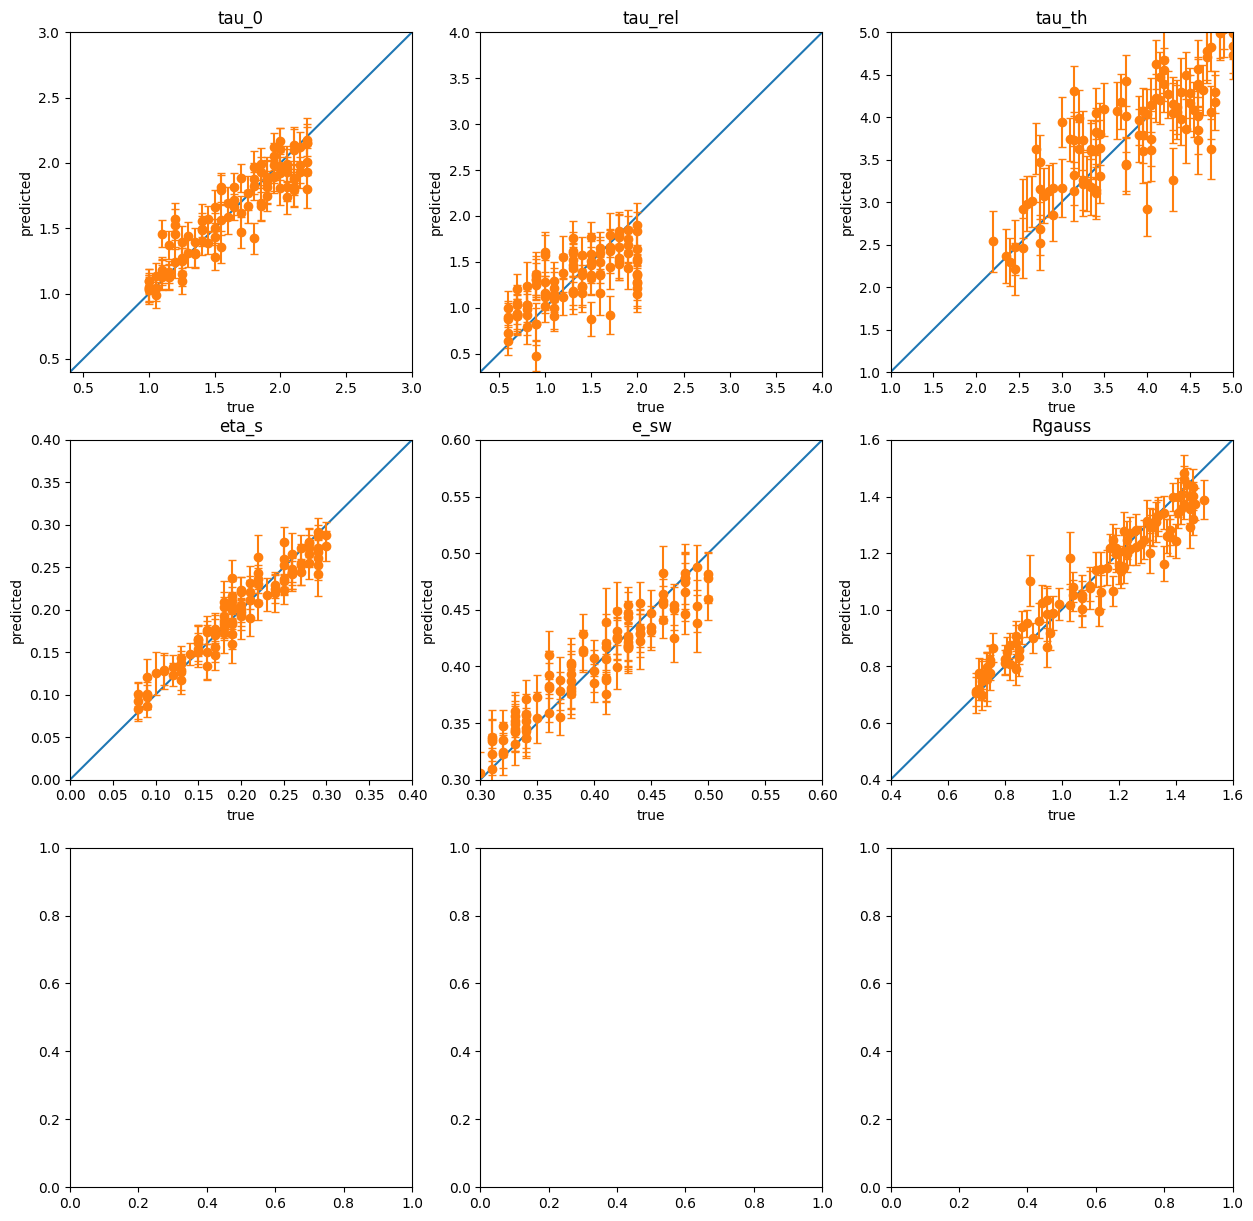

In [21]:
import matplotlib.pyplot as plt

figure, axis = plt.subplots(3, 3, figsize=(15, 15))

axis[0, 0].set_title("tau_0")
axis[0, 0].set_xlim([0.4, 3.0])
axis[0, 0].set_ylim([0.4, 3.0])
axis[0, 0].plot([0, 1, 2, 3, 4, 5, 6])
axis[0, 0].errorbar(Y_valid[['tau_0']], means_validation[:, 0], yerr=tf.math.abs(errors_validation[:, 0]), fmt='o', capsize=3)
axis[0, 0].set_xlabel("true")
axis[0, 0].set_ylabel("predicted")


axis[0, 1].set_title("tau_rel")
axis[0, 1].set_xlim(0.3,4.0)
axis[0, 1].set_ylim(0.3,4.0)
axis[0, 1].plot([0, 1, 2, 3, 4])
axis[0, 1].errorbar(Y_valid[['tau_rel']], means_validation[:, 1], yerr=tf.math.abs(errors_validation[:, 1]), fmt='o', capsize=3)
axis[0, 1].set_xlabel("true")
axis[0, 1].set_ylabel("predicted")

axis[0, 2].set_title("tau_th")
axis[0, 2].set_xlim(1.0,5.0)
axis[0, 2].set_ylim(1.0,5.0)
axis[0, 2].plot([0, 1, 2, 3, 4])
axis[0, 2].errorbar(Y_valid[['tau_th']], means_validation[:, 2], yerr=tf.math.abs(errors_validation[:, 2]), fmt='o', capsize=3)
axis[0, 2].set_xlabel("true")
axis[0, 2].set_ylabel("predicted")

axis[1, 0].set_title("eta_s")
axis[1, 0].set_xlim(0.0,0.4)
axis[1, 0].set_ylim(0.0,0.4)
axis[1, 0].plot([0, 1, 2, 3])
axis[1, 0].errorbar(Y_valid[['eta_s']], means_validation[:, 3], yerr=tf.math.abs(errors_validation[:, 3]), fmt='o', capsize=3)
axis[1, 0].set_xlabel("true")
axis[1, 0].set_ylabel("predicted")

axis[1, 1].set_title("e_sw")
axis[1, 1].set_xlim(0.3, 0.6)
axis[1, 1].set_ylim(0.3, 0.6)
axis[1, 1].plot([0, 1, 2, 3])
axis[1, 1].errorbar(Y_valid[['e_sw']], means_validation[:, 4], yerr=tf.math.abs(errors_validation[:, 4]), fmt='o', capsize=3)
axis[1, 1].set_xlabel("true")
axis[1, 1].set_ylabel("predicted")

axis[1, 2].set_title("Rgauss")
axis[1, 2].set_xlim(0.4, 1.6)
axis[1, 2].set_ylim(0.4, 1.6)
axis[1, 2].plot([0, 1, 2, 3])
axis[1, 2].errorbar(Y_valid[['Rgauss']], means_validation[:, 5], yerr=tf.math.abs(errors_validation[:, 5]), fmt='o', capsize=3)
axis[1, 2].set_xlabel("true")
axis[1, 2].set_ylabel("predicted")

## Ensemble validation analytics

Point accuracy and uncertainty calibration are evaluated separately on simulations with known parameters. `std_RMSE` is computed in standardized target space, while MAE, bias, and sharpness are reported in each parameter's physical units. Good uncertainty calibration has coverage near 0.68 and 0.95, mean standardized residual near zero, and mean squared standardized residual near one. Lower Gaussian NLL is better because it rewards accuracy while penalizing unnecessarily broad intervals.

In [22]:
parameter_names = list(Y_valid.columns)
y_true_physical = Y_valid.to_numpy()
residual_norm = ensemble_mean_norm - Y_valid_norm
residual_physical = means_validation - y_true_physical
sigma_norm = np.sqrt(safe_total_variance_norm)
sigma_physical = errors_validation
z_scores = (Y_valid_norm - ensemble_mean_norm) / sigma_norm

std_rmse = np.sqrt(np.mean(np.square(residual_norm), axis=0))
mae = np.mean(np.abs(residual_physical), axis=0)
bias = np.mean(residual_physical, axis=0)
ss_res = np.sum(np.square(residual_physical), axis=0)
ss_tot = np.sum(
    np.square(y_true_physical - y_true_physical.mean(axis=0)), axis=0
)
r2 = 1.0 - ss_res / ss_tot
gaussian_nll = np.mean(
    0.5
    * (
        np.square(residual_norm) / safe_total_variance_norm
        + np.log(safe_total_variance_norm)
        + np.log(2.0 * np.pi)
    ),
    axis=0,
)
coverage_68 = np.mean(np.abs(z_scores) <= 1.0, axis=0)
coverage_95 = np.mean(np.abs(z_scores) <= 1.96, axis=0)
mean_z = np.mean(z_scores, axis=0)
mean_z2 = np.mean(np.square(z_scores), axis=0)
sharpness = np.mean(sigma_physical, axis=0)

metrics = pd.DataFrame(
    {
        "std_RMSE": std_rmse,
        "MAE_physical": mae,
        "bias_physical": bias,
        "R2": r2,
        "Gaussian_NLL": gaussian_nll,
        "coverage_68": coverage_68,
        "coverage_95": coverage_95,
        "mean_z": mean_z,
        "mean_z2": mean_z2,
        "sharpness_physical": sharpness,
    },
    index=parameter_names,
)
display(metrics.round(4))

summary = pd.Series(
    {
        "macro_std_RMSE": std_rmse.mean(),
        "macro_R2": r2.mean(),
        "mean_Gaussian_NLL": gaussian_nll.mean(),
        "overall_coverage_68": np.mean(np.abs(z_scores) <= 1.0),
        "overall_coverage_95": np.mean(np.abs(z_scores) <= 1.96),
        "overall_mean_z": z_scores.mean(),
        "overall_mean_z2": np.mean(np.square(z_scores)),
    },
    name="ensemble_validation_summary",
)
display(summary.to_frame().round(4))

,std_RMSE,MAE_physical,bias_physical,R2,Gaussian_NLL,coverage_68,coverage_95,mean_z,mean_z2,sharpness_physical
tau_0,0.4091,0.1146,-0.0067,0.8473,0.5880,0.60,0.84,0.0238,1.6718,0.1165
tau_rel,0.7488,0.2523,-0.0146,0.4781,1.4245,0.48,0.79,0.0451,2.5383,0.2021
tau_th,0.5572,0.3316,0.0260,0.6860,0.9474,0.63,0.83,-0.0947,1.8000,0.3230
eta_s,0.2715,0.0141,0.0001,0.9181,0.0769,0.68,0.98,-0.0018,0.8778,0.0182
e_sw,0.3340,0.0154,0.0028,0.8829,0.3144,0.69,0.95,-0.1605,0.9776,0.0195
Rgauss,0.2908,0.0513,-0.0099,0.9279,0.1625,0.64,0.92,0.1727,1.2131,0.0601


,ensemble_validation_summary
macro_std_RMSE,0.4353
macro_R2,0.7901
mean_Gaussian_NLL,0.5856
overall_coverage_68,0.6200
overall_coverage_95,0.8850
overall_mean_z,-0.0026
overall_mean_z2,1.5131


## Noisy closure and coverage

The validation simulations have known parameters. Each validation input is
perturbed repeatedly with the 7.7-GeV experimental per-bin errors, using the
same sampling and preprocessing as the experimental point. Coverage below
therefore tests the combined experimental-input, ensemble, and learned-residual
uncertainty under this noise model. It assumes independent experimental bins.


In [23]:
noisy_closure_predictions = np.stack(noisy_closure_predictions, axis=0)
(
    noisy_mean_norm,
    noisy_experimental_variance_norm,
    noisy_ensemble_variance_norm,
    noisy_learned_residual_variance_norm,
    noisy_total_variance_norm,
) = decompose_mc_ensemble(noisy_closure_predictions)
(
    noisy_mean_physical,
    noisy_experimental_std_physical,
    noisy_ensemble_std_physical,
    noisy_learned_residual_std_physical,
    noisy_total_std_physical,
) = mc_components_to_physical(
    noisy_mean_norm,
    noisy_experimental_variance_norm,
    noisy_ensemble_variance_norm,
    noisy_learned_residual_variance_norm,
    noisy_total_variance_norm,
)

safe_noisy_total_variance_norm = np.maximum(noisy_total_variance_norm, 1e-12)
noisy_z_scores = (Y_valid_norm - noisy_mean_norm) / np.sqrt(
    safe_noisy_total_variance_norm
)
noisy_residual_norm = noisy_mean_norm - Y_valid_norm
noisy_residual_physical = noisy_mean_physical - Y_valid.to_numpy()

noisy_closure_metrics = pd.DataFrame(
    {
        "std_RMSE": np.sqrt(np.mean(np.square(noisy_residual_norm), axis=0)),
        "MAE_physical": np.mean(np.abs(noisy_residual_physical), axis=0),
        "bias_physical": np.mean(noisy_residual_physical, axis=0),
        "coverage_68": np.mean(np.abs(noisy_z_scores) <= 1.0, axis=0),
        "coverage_95": np.mean(np.abs(noisy_z_scores) <= 1.96, axis=0),
        "mean_z": np.mean(noisy_z_scores, axis=0),
        "mean_z2": np.mean(np.square(noisy_z_scores), axis=0),
        "experimental_std_physical": noisy_experimental_std_physical.mean(axis=0),
        "ensemble_std_physical": noisy_ensemble_std_physical.mean(axis=0),
        "learned_residual_std_physical": noisy_learned_residual_std_physical.mean(axis=0),
        "total_std_physical": noisy_total_std_physical.mean(axis=0),
    },
    index=Y_valid.columns,
)
display(noisy_closure_metrics.round(4))

noisy_closure_summary = pd.Series(
    {
        "macro_std_RMSE": noisy_closure_metrics["std_RMSE"].mean(),
        "overall_coverage_68": np.mean(np.abs(noisy_z_scores) <= 1.0),
        "overall_coverage_95": np.mean(np.abs(noisy_z_scores) <= 1.96),
        "overall_mean_z": noisy_z_scores.mean(),
        "overall_mean_z2": np.mean(np.square(noisy_z_scores)),
    },
    name="noisy_closure_summary",
)
display(noisy_closure_summary.to_frame().round(4))


,std_RMSE,MAE_physical,bias_physical,coverage_68,coverage_95,mean_z,mean_z2,experimental_std_physical,ensemble_std_physical,learned_residual_std_physical,total_std_physical
tau_0,0.4808,0.1403,0.0724,0.90,0.99,-0.3010,0.4941,0.2291,0.0714,0.0708,0.2507
tau_rel,0.7527,0.2602,-0.0210,0.87,0.99,0.0329,0.5014,0.4246,0.1242,0.0996,0.4542
tau_th,0.6069,0.3778,0.1250,0.88,1.00,-0.1646,0.3799,0.6939,0.2128,0.1719,0.7468
eta_s,0.3383,0.0179,0.0064,0.98,1.00,-0.1513,0.2184,0.0434,0.0130,0.0121,0.0470
e_sw,0.3973,0.0186,-0.0022,0.97,1.00,0.0312,0.2183,0.0453,0.0118,0.0125,0.0485
Rgauss,0.3550,0.0639,0.0110,0.92,1.00,-0.0690,0.2872,0.1376,0.0417,0.0463,0.1513


,noisy_closure_summary
macro_std_RMSE,0.4885
overall_coverage_68,0.9200
overall_coverage_95,0.9967
overall_mean_z,-0.1036
overall_mean_z2,0.3499
